# Lab 4-1 — Visualization notebook

**This notebook is a working tool, not a deliverable — you do NOT submit it.**

It contains no logic of its own: it imports your finished functions from `../src/lab04_1.py`
and plots their output. If a cell below fails, the bug is in your `.py`, not in the plot.

Your job: complete the three plot cells, then **export each figure and paste it into
`report.pdf`** (right-click → Save image as…, or `plt.savefig('fig1.png', dpi=150)`).
Figures 1–3 are required by the report template.

In [1]:
import sys
sys.path.insert(0, '../src')
%matplotlib inline
import matplotlib.pyplot as plt
import numpy as np
import lab04_1

X, y = lab04_1.load_data('../data/press_qc.csv')
X_train, X_val, y_train, y_val = lab04_1.train_val_split(X, y)
results = lab04_1.run_experiment(X, y)
results

Matplotlib is building the font cache; this may take a moment.


{'0.01': {'final_train_loss': 0.6065,
  'max_train_loss': 0.6853,
  'final_val_loss': 0.6049,
  'final_val_accuracy': 0.7063,
  'best_val_accuracy': 0.7063},
 '1.0': {'final_train_loss': 0.2822,
  'max_train_loss': 0.6247,
  'final_val_loss': 0.3608,
  'final_val_accuracy': 0.8812,
  'best_val_accuracy': 0.8938},
 '100.0': {'final_train_loss': 0.7231,
  'max_train_loss': 19.4281,
  'final_val_loss': 0.7168,
  'final_val_accuracy': 0.7063,
  'best_val_accuracy': 0.7063}}

## Plot 1 — The data, in the space the network sees

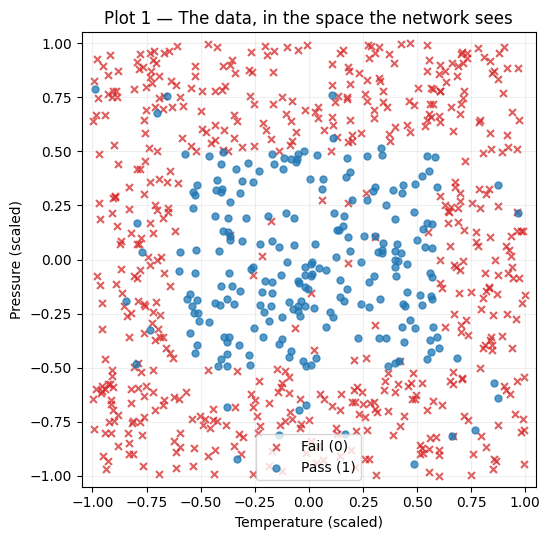

In [2]:
# ============ TODO (Plot 1) ============
# Scatter X[:, 0] (temperature, scaled) against X[:, 1] (pressure, scaled),
# one marker style per class of y. Title, axis labels, legend.
# Look at the shape of the region where the passing parts sit.
# =======================================

fig, ax = plt.subplots(figsize=(8, 5.5))
labels = y.ravel()

for cls, label, color, marker in [
    (0, "Fail (0)", "tab:red", "x"),
    (1, "Pass (1)", "tab:blue", "o"),
]:
    mask = labels == cls
    ax.scatter(
        X[mask, 0], X[mask, 1],
        label=label, color=color, marker=marker,
        s=25, alpha=0.75,
    )

ax.set(
    title="Plot 1 — The data, in the space the network sees",
    xlabel="Temperature (scaled)",
    ylabel="Pressure (scaled)",
    xlim=(-1.05, 1.05),
    ylim=(-1.05, 1.05),
)
ax.set_aspect("equal", adjustable="box")
ax.legend()
ax.grid(alpha=0.2)

fig.tight_layout()
fig.savefig("fig1.png", dpi=200, bbox_inches="tight")
plt.show()


## Plot 2 — Loss curves for three learning rates

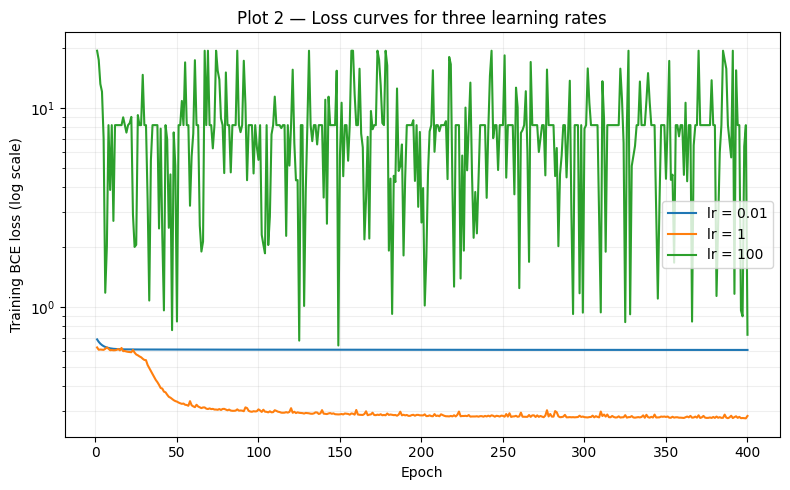

In [3]:
# ============ TODO (Plot 2) ============
# Train once for each learning rate in lab04_1.LEARNING_RATES and draw all three
# history['train_loss'] curves on one pair of axes, against epoch.
# A log scale on the y axis keeps the diverged run readable. Legend by learning rate.
# =======================================

fig, ax = plt.subplots(figsize=(8, 5))

for lr in lab04_1.LEARNING_RATES:
    _, history = lab04_1.train(
        X_train, y_train, X_val, y_val, lr=lr,
    )
    epoch_numbers = np.arange(1, len(history["train_loss"]) + 1)
    ax.plot(
        epoch_numbers,
        history["train_loss"],
        label=f"lr = {lr:g}",
        linewidth=1.5,
    )

ax.set_yscale("log")
ax.set(
    title="Plot 2 — Loss curves for three learning rates",
    xlabel="Epoch",
    ylabel="Training BCE loss (log scale)",
)
ax.legend()
ax.grid(which="both", alpha=0.2)

fig.tight_layout()
fig.savefig("fig2.png", dpi=200, bbox_inches="tight")
plt.show()


## Plot 3 — What the trained network decided

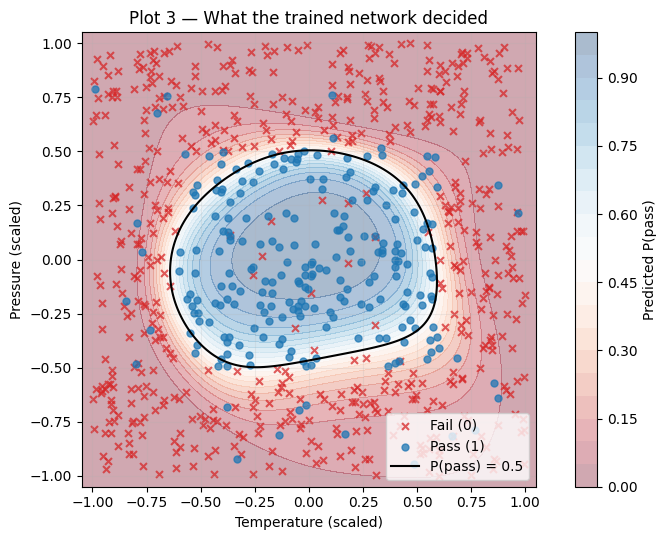

In [4]:
# ============ TODO (Plot 3) ============
# Train with lr=1.0, then draw the 0.5 contour of the predicted probability on top
# of the Plot 1 scatter. Compare the boundary with the region you saw there.
#
# The grid is boilerplate, so here it is:
#   g = np.linspace(-1.05, 1.05, 200)
#   gx, gy = np.meshgrid(g, g)
#   prob = lab04_1.forward(np.column_stack([gx.ravel(), gy.ravel()]), params)['a2'].reshape(gx.shape)
# then ax.contourf(gx, gy, prob, ...) and ax.contour(gx, gy, prob, levels=[0.5], colors='k').
# =======================================

params, _ = lab04_1.train(
    X_train, y_train, X_val, y_val, lr=1.0,
)

g = np.linspace(-1.05, 1.05, 200)
gx, gy = np.meshgrid(g, g)
grid_X = np.column_stack([gx.ravel(), gy.ravel()])
prob = lab04_1.forward(grid_X, params)["a2"].reshape(gx.shape)

fig, ax = plt.subplots(figsize=(8, 5.5))
background = ax.contourf(
    gx, gy, prob,
    levels=np.linspace(0.0, 1.0, 21),
    cmap="RdBu", alpha=0.35,
    vmin=0.0, vmax=1.0,
)
fig.colorbar(background, ax=ax, label="Predicted P(pass)")

ax.contour(
    gx, gy, prob,
    levels=[0.5], colors="k", linewidths=1.5,
)

labels = y.ravel()
for cls, label, color, marker in [
    (0, "Fail (0)", "tab:red", "x"),
    (1, "Pass (1)", "tab:blue", "o"),
]:
    mask = labels == cls
    ax.scatter(
        X[mask, 0], X[mask, 1],
        label=label, color=color, marker=marker,
        s=25, alpha=0.75,
    )

ax.plot([], [], color="k", linewidth=1.5, label="P(pass) = 0.5")
ax.set(
    title="Plot 3 — What the trained network decided",
    xlabel="Temperature (scaled)",
    ylabel="Pressure (scaled)",
    xlim=(-1.05, 1.05),
    ylim=(-1.05, 1.05),
)
ax.set_aspect("equal", adjustable="box")
ax.legend()
ax.grid(alpha=0.2)

fig.tight_layout()
fig.savefig("fig3.png", dpi=200, bbox_inches="tight")
plt.show()
